Aditi Shankar

QBIO 465 Capstone Project

5/4/26

This project develops a multimodal machine learning approach to classify Alzheimer’s disease using both clinical and imaging data. The study aims to evaluate whether combining clinical and demographic variables with MRI-derived features improves classification performance compared to using either modality alone. To address this, MRI images will be processed using a convolutional neural network (CNN) to extract feature representations, which will then be combined with clinical patient data. The resulting feature vector will be used as input to a multilayer perceptron (MLP) classifier to generate final predictions. Model performance will be compared across clinical-only, MRI-only, and multimodal approaches using standard evaluation metrics. It is expected that the multimodal model will outperform single-modality models, as clinical and imaging data provide complementary information about disease status.


### **Data Loading/Preprocessing**

**Load clinical data**

In [ ]:
import os
import random
import numpy as np
import tensorflow as tf
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import json

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, recall_score, roc_auc_score, f1_score

In [ ]:
oasis_df = pd.read_excel("oasis_clinical.xlsx")
print(oasis_df.shape)
oasis_df.head()

(436, 12)


,ID,M/F,Hand,Age,Educ,SES,MMSE,CDR,eTIV,nWBV,ASF,Delay
0,OAS1_0001_MR1,F,R,74,2.0,3.0,29.0,0.0,1344,0.743,1.306,NaN
1,OAS1_0002_MR1,F,R,55,4.0,1.0,29.0,0.0,1147,0.810,1.531,NaN
2,OAS1_0003_MR1,F,R,73,4.0,3.0,27.0,0.5,1454,0.708,1.207,NaN
3,OAS1_0004_MR1,M,R,28,NaN,NaN,NaN,NaN,1588,0.803,1.105,NaN
4,OAS1_0005_MR1,M,R,18,NaN,NaN,NaN,NaN,1737,0.848,1.010,NaN


In [ ]:
oasis_df = oasis_df[["ID", "M/F", "Age", "Educ", "nWBV", "CDR"]]
oasis_df.head()

,ID,M/F,Age,Educ,nWBV,CDR
0,OAS1_0001_MR1,F,74,2.0,0.743,0.0
1,OAS1_0002_MR1,F,55,4.0,0.810,0.0
2,OAS1_0003_MR1,F,73,4.0,0.708,0.5
3,OAS1_0004_MR1,M,28,NaN,0.803,NaN
4,OAS1_0005_MR1,M,18,NaN,0.848,NaN


In [ ]:
# drop rows with NAN
oasis_df = oasis_df.dropna()
print(oasis_df.shape)
oasis_df.head()

(235, 6)


,ID,M/F,Age,Educ,nWBV,CDR
0,OAS1_0001_MR1,F,74,2.0,0.743,0.0
1,OAS1_0002_MR1,F,55,4.0,0.810,0.0
2,OAS1_0003_MR1,F,73,4.0,0.708,0.5
8,OAS1_0010_MR1,M,74,5.0,0.689,0.0
9,OAS1_0011_MR1,F,52,3.0,0.827,0.0


In [ ]:
# creating the binary target (0 = non-demented, > 0 = demented or Alzheimer's related)
oasis_df["target"] = oasis_df["CDR"].apply(lambda x: 0 if x == 0 else 1)
# oasis_df.head()

target
0    135
1    100
Name: count, dtype: int64


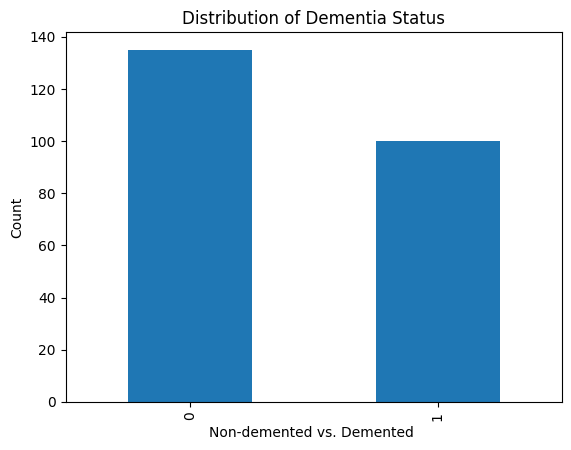

In [ ]:
# count the number of demented vs. non-demented
print(oasis_df["target"].value_counts())

# bar graph of distribution
oasis_df["target"].value_counts().plot(kind="bar")
plt.title("Distribution of Dementia Status")
plt.xlabel("Non-demented vs. Demented ")
plt.ylabel("Count")
plt.show()

In [ ]:
# encode the categorical variable - sex
oasis_df = pd.get_dummies(oasis_df, columns=["M/F"], drop_first=True)
oasis_df.head()

,ID,Age,Educ,nWBV,CDR,target,M/F_M
0,OAS1_0001_MR1,74,2.0,0.743,0.0,0,False
1,OAS1_0002_MR1,55,4.0,0.810,0.0,0,False
2,OAS1_0003_MR1,73,4.0,0.708,0.5,1,False
8,OAS1_0010_MR1,74,5.0,0.689,0.0,0,True
9,OAS1_0011_MR1,52,3.0,0.827,0.0,0,False


**Load MRI scan data**

In [ ]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle.json


{'kaggle.json': b'{"username":"aditishankar2","key":"70f122eb0452ee78d9fe69d119eacfc3"}'}

In [ ]:
import os

os.makedirs('/root/.kaggle', exist_ok=True)

!mv kaggle.json /root/.kaggle/
!chmod 600 /root/.kaggle/kaggle.json

!pip install kagglehub

import kagglehub

# Download latest version
path = kagglehub.dataset_download("ninadaithal/imagesoasis")

print("Path to dataset files:", path)

100%|██████████| 1.23G/1.23G [00:19<00:00, 68.4MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ninadaithal/imagesoasis/versions/1


In [ ]:
print(os.listdir(path))

data_root = os.path.join(path, "Data")
print(os.listdir(data_root))

['Data']
['Very mild Dementia', 'Moderate Dementia', 'Non Demented', 'Mild Dementia']


In [ ]:
# match oasis_df (clinical data only patients) to mri scans
clinical_ids = set(oasis_df["ID"].astype(str))

patient_dict = defaultdict(list)
labels_dict = {}

for class_name in sorted(os.listdir(data_root)):
    class_path = os.path.join(data_root, class_name)

    label = 0 if "Non" in class_name else 1

    for img_name in sorted(os.listdir(class_path)):
        if not img_name.endswith(".jpg"):
            continue

        patient_id = "_".join(img_name.split("_")[:3])

        if patient_id in clinical_ids:
            img_path = os.path.join(class_path, img_name)
            patient_dict[patient_id].append(img_path)
            labels_dict[patient_id] = label

print("\nClinical patients:", len(clinical_ids))
print("MRI patients matched:", len(patient_dict))


Clinical patients: 235
MRI patients matched: 200


In [ ]:
# matched patient IDs
label_map = oasis_df.set_index("ID")["target"].to_dict()

common_ids = sorted([pid for pid in patient_dict.keys() if pid in label_map])

print("\nNumber of shared patients:", len(common_ids))
print("First 10 shared IDs:", common_ids[:10])

# Filter clinical dataframe to shared patients only
oasis_df = oasis_df[oasis_df["ID"].isin(common_ids)].copy()

print("\nFinal clinical dataset size:", oasis_df.shape)
print("Final unique patients:", oasis_df["ID"].nunique())

common_ids = sorted(common_ids)

# final shared IDs saved to reload after a crash
with open("common_ids.json", "w") as f:
    json.dump(common_ids, f)


Number of shared patients: 200
First 10 shared IDs: ['OAS1_0001_MR1', 'OAS1_0002_MR1', 'OAS1_0003_MR1', 'OAS1_0010_MR1', 'OAS1_0011_MR1', 'OAS1_0013_MR1', 'OAS1_0015_MR1', 'OAS1_0016_MR1', 'OAS1_0018_MR1', 'OAS1_0019_MR1']

Final clinical dataset size: (200, 7)
Final unique patients: 200


In [ ]:
# function to obtain/store each model's metrics for final comparison

def get_metrics(y_true, y_pred, y_prob):
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Recall (Class 1)": recall_score(y_true, y_pred),
        "F1 Score": f1_score(y_true, y_pred),
        "ROC AUC": roc_auc_score(y_true, y_prob)
    }

### **Model 1: Clinical-only with Logistic Regression**

In [ ]:
X = oasis_df[["Age", "M/F_M", "Educ", "nWBV"]]
y = oasis_df["target"]

# split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# standardize
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Model 1: logistic regression
model1 = LogisticRegression(random_state=42, max_iter=1000)
model1.fit(X_train, y_train)
y_pred = model1.predict(X_test)

y_prob = model1.predict_proba(X_test)[:, 1]

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))
print("ROC AUC:", roc_auc_score(y_test, y_prob))

# store clinical model metrics

clinical_metrics = get_metrics(y_test, y_pred, y_prob)

Accuracy: 0.75
              precision    recall  f1-score   support

           0       0.73      0.92      0.81        24
           1       0.80      0.50      0.62        16

    accuracy                           0.75        40
   macro avg       0.77      0.71      0.72        40
weighted avg       0.76      0.75      0.74        40

ROC AUC: 0.7864583333333334


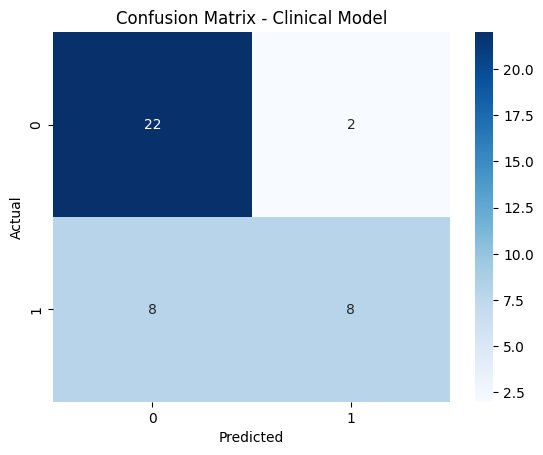

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Clinical Model")
plt.show()

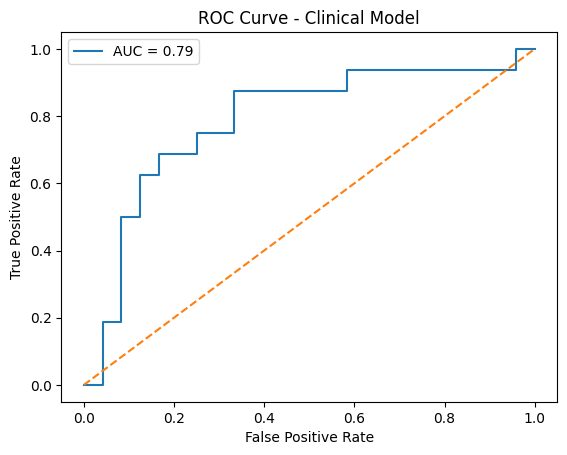

In [ ]:
from sklearn.metrics import roc_curve, auc

y_prob = model1.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, y_prob)
roc_auc = auc(fpr, tpr)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Clinical Model")
plt.legend()
plt.show()

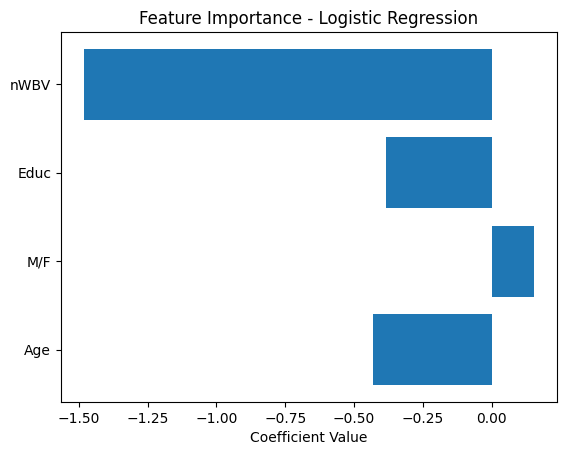

In [ ]:
features = ["Age", "M/F", "Educ", "nWBV"]
coefficients = model1.coef_[0]

plt.barh(features, coefficients)
plt.xlabel("Coefficient Value")
plt.title("Feature Importance - Logistic Regression")
plt.show()

### **Model 2: MRI-only with Convolutional Neural Network**

In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from PIL import Image

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, roc_curve, auc
from sklearn.utils.class_weight import compute_class_weight

import seaborn as sns
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
# each patient has many slices so choose 5 random slices for each patient
N_SLICES = 5
IMG_SIZE = 128

# sort the slice names of the files
def slice_sort_key(path):
    name = os.path.splitext(os.path.basename(path))[0]
    try:
        return int(name.split("_")[-1])
    except:
        return 0

In [ ]:
def select_n_slices(paths, n=N_SLICES):
    paths = sorted(paths, key=slice_sort_key)
    if len(paths) >= n:
        idxs = np.linspace(0, len(paths) - 1, n, dtype=int)
        return [paths[i] for i in idxs]
    elif len(paths) > 0:
        return paths + [paths[-1]] * (n - len(paths))
    else:
        return []

In [ ]:
# visualize one patient's slices

def visualize_patient_slices(pid, n_slices=N_SLICES):
    paths = select_n_slices(patient_dict[pid], n=n_slices)

    plt.figure(figsize=(15, 3))

    for i, img_path in enumerate(paths):
        img = mpimg.imread(img_path)

        if len(img.shape) == 3:
            img = np.mean(img, axis=2)

        plt.subplot(1, n_slices, i + 1)
        plt.imshow(img, cmap="gray")
        plt.axis("off")
        plt.title(f"Slice {i+1}")

    plt.suptitle(f"Patient {pid} - MRI Slices")
    plt.show()


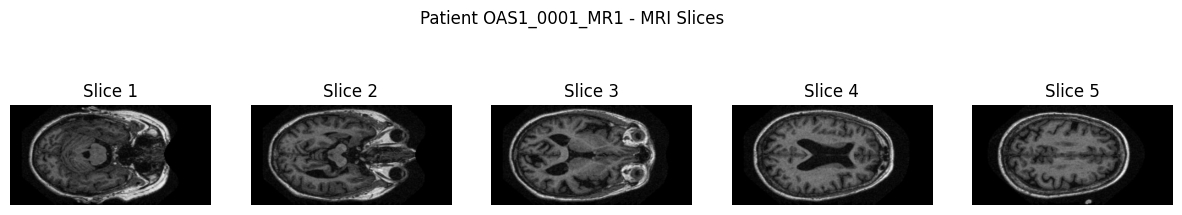

Patient: OAS1_0001_MR1
Label: 0


In [ ]:
sample_patient = common_ids[0]
visualize_patient_slices(sample_patient)
print("Patient:", sample_patient)
print("Label:", label_map[sample_patient])

In [ ]:
# split by patient
y_all = [label_map[pid] for pid in common_ids]

train_ids, temp_ids = train_test_split(
    common_ids, test_size=0.30, random_state=42, stratify=y_all
)

temp_labels = [label_map[pid] for pid in temp_ids]

val_ids, test_ids = train_test_split(
    temp_ids, test_size=0.50, random_state=42, stratify=temp_labels
)

print("Train patients:", len(train_ids))
print("Val patients:", len(val_ids))
print("Test patients:", len(test_ids))

Train patients: 140
Val patients: 30
Test patients: 30


In [ ]:
def load_image(img_path, img_size=IMG_SIZE):
    img = Image.open(img_path).convert("L")
    img = img.resize((img_size, img_size))
    img = np.array(img).astype("float32") / 255.0
    return img

In [ ]:
# load MRI slices as arrays

def load_slice_dataset(patient_ids, n_slices=N_SLICES, img_size=IMG_SIZE):
    X = []
    y = []

    for pid in patient_ids:
        paths = select_n_slices(patient_dict[pid], n=n_slices)

        for img_path in paths:
            img = load_image(img_path, img_size=img_size)
            img = np.expand_dims(img, axis=-1)

            X.append(img)
            y.append(label_map[pid])

    return np.array(X), np.array(y)

In [ ]:
X_train, y_train = load_slice_dataset(train_ids)
X_val, y_val = load_slice_dataset(val_ids)
X_test, y_test = load_slice_dataset(test_ids)

print(X_train.shape, y_train.shape)
print(X_val.shape, y_val.shape)
print(X_test.shape, y_test.shape)

(700, 128, 128, 1) (700,)
(150, 128, 128, 1) (150,)
(150, 128, 128, 1) (150,)


In [ ]:
# class balance
print("Train class counts:", np.bincount(y_train))
print("Val class counts:", np.bincount(y_val))
print("Test class counts:", np.bincount(y_test))

classes = np.unique(y_train)
class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = {int(cls): float(weight) for cls, weight in zip(classes, class_weights_values)}
print(class_weights)

Train class counts: [415 285]
Val class counts: [90 60]
Test class counts: [90 60]
{0: 0.8433734939759037, 1: 1.2280701754385965}


In [ ]:
# CNN model

model2 = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 1)),
    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Flatten(),
    layers.Dense(128, activation='relu', name="embedding"),
    layers.Dropout(0.5),
    layers.Dense(1, activation='sigmoid')
])


In [ ]:
model2.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model2.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding (Dense)               │ (None, 128)            │     3,211,392 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,304,193 (12.60 MB)

 Trainable params: 3,304,193 (12.60 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)

history = model2.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=15,
    batch_size=16,
    callbacks=[early_stop]
)

Epoch 1/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 25s 457ms/step - accuracy: 0.5929 - loss: 0.6761 - val_accuracy: 0.6000 - val_loss: 0.6764
Epoch 2/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 23s 518ms/step - accuracy: 0.6000 - loss: 0.6727 - val_accuracy: 0.5800 - val_loss: 0.6855
Epoch 3/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 38s 452ms/step - accuracy: 0.6114 - loss: 0.6464 - val_accuracy: 0.5467 - val_loss: 0.6932
Epoch 4/15
44/44 ━━━━━━━━━━━━━━━━━━━━ 22s 492ms/step - accuracy: 0.6714 - loss: 0.6176 - val_accuracy: 0.5400 - val_loss: 0.6868


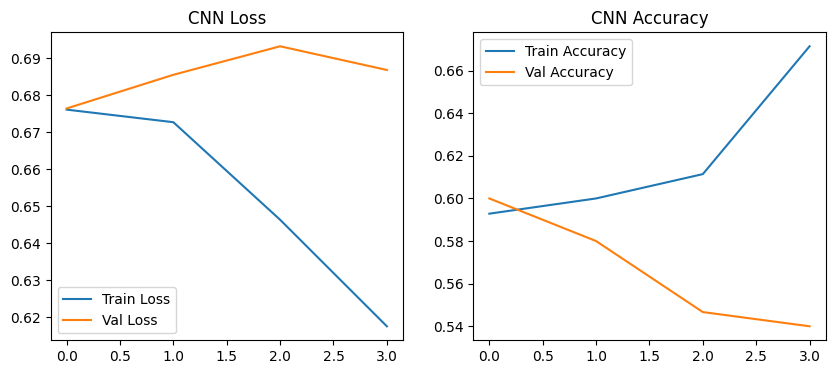

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history.history["loss"], label="Train Loss")
plt.plot(history.history["val_loss"], label="Val Loss")
plt.legend()
plt.title("CNN Loss")

plt.subplot(1,2,2)
plt.plot(history.history["accuracy"], label="Train Accuracy")
plt.plot(history.history["val_accuracy"], label="Val Accuracy")
plt.legend()
plt.title("CNN Accuracy")

plt.show()

In [ ]:
# patient level prediction
# Predictions will be generated at the slice level and aggregated to produce subject-level classifications. (average of the slices)
def predict_patient(pid, n_slices=N_SLICES, img_size=IMG_SIZE):
    paths = select_n_slices(patient_dict[pid], n=n_slices)
    imgs = []

    for img_path in paths:
        img = load_image(img_path, img_size=img_size)
        img = np.expand_dims(img, axis=-1)
        imgs.append(img)

    imgs = np.array(imgs)
    probs = model2.predict(imgs, verbose=0).ravel()
    return probs.mean()

In [ ]:
y_test_true = np.array([label_map[pid] for pid in test_ids])
y_test_prob = np.array([predict_patient(pid) for pid in test_ids])
y_test_pred = (y_test_prob >= 0.35).astype(int)

print("Accuracy:", accuracy_score(y_test_true, y_test_pred))
print(classification_report(y_test_true, y_test_pred))
print("ROC AUC:", roc_auc_score(y_test_true, y_test_prob))

mri_metrics = get_metrics(y_test_true, y_test_pred, y_test_prob)

Accuracy: 0.4
              precision    recall  f1-score   support

           0       0.00      0.00      0.00        18
           1       0.40      1.00      0.57        12

    accuracy                           0.40        30
   macro avg       0.20      0.50      0.29        30
weighted avg       0.16      0.40      0.23        30

ROC AUC: 0.4351851851851851


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


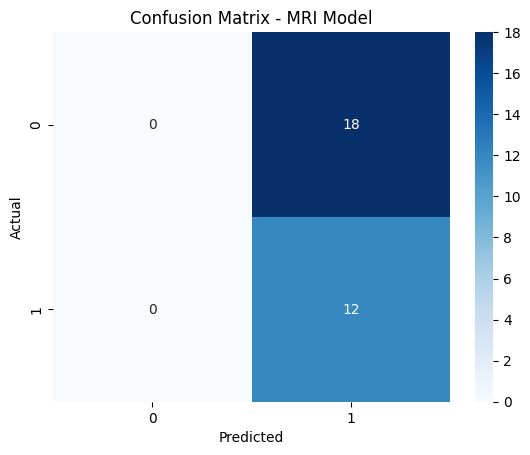

In [ ]:
cm = confusion_matrix(y_test_true, y_test_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - MRI Model")
plt.show()

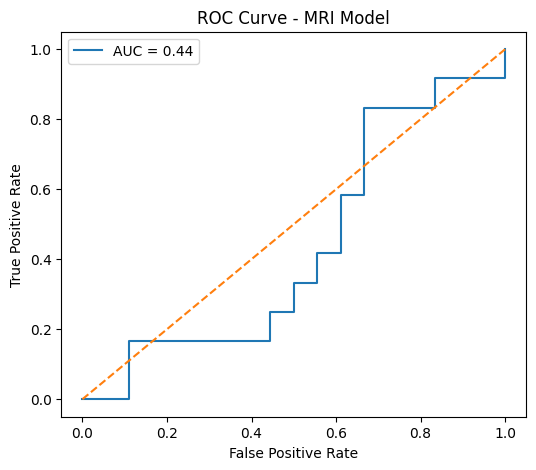

In [ ]:
fpr, tpr, _ = roc_curve(y_test_true, y_test_prob)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - MRI Model")
plt.legend()
plt.show()

**Model 3: Multimodal (Clinical + MRI) with Multilayer Perceptron**

In [ ]:
features_updated = ["Age", "M/F_M", "Educ", "nWBV"]

In [ ]:
# extracting one MRI embedding per patient from the CNN to combine with the clinical variables

def extract_patient_embedding(pid, n_slices=N_SLICES, img_size=IMG_SIZE):
    paths = select_n_slices(patient_dict[pid], n=n_slices)
    imgs = []

    for img_path in paths:
        img = load_image(img_path, img_size=img_size)
        img = np.expand_dims(img, axis=-1)
        imgs.append(img)

    imgs = np.array(imgs)
    emb = model2.predict(imgs, verbose=0)
    return emb.mean(axis=0)

In [ ]:
# multimodal component

def build_multimodal_dataset(patient_ids):
    # clinical data
    X_clinical = oasis_df.set_index("ID").loc[patient_ids, features_updated].astype("float32").values

    # MRI embeddings
    X_mri = np.array([extract_patient_embedding(pid, N_SLICES, IMG_SIZE) for pid in patient_ids], dtype="float32")

    # labels
    y = np.array([label_map[pid] for pid in patient_ids], dtype=int)

    return X_clinical, X_mri, y

In [ ]:
X_train_clinical, X_train_mri, y_train_multi = build_multimodal_dataset(train_ids)
X_val_clinical, X_val_mri, y_val_multi = build_multimodal_dataset(val_ids)
X_test_clinical, X_test_mri, y_test_multi = build_multimodal_dataset(test_ids)

print(X_train_clinical.shape, X_train_mri.shape, y_train_multi.shape)
print(X_val_clinical.shape, X_val_mri.shape, y_val_multi.shape)
print(X_test_clinical.shape, X_test_mri.shape, y_test_multi.shape)

(140, 4) (140, 1) (140,)
(30, 4) (30, 1) (30,)
(30, 4) (30, 1) (30,)


In [ ]:
# scaling

clinical_scaler = StandardScaler()
mri_scaler = StandardScaler()

X_train_clinical = clinical_scaler.fit_transform(X_train_clinical)
X_val_clinical = clinical_scaler.transform(X_val_clinical)
X_test_clinical = clinical_scaler.transform(X_test_clinical)

X_train_mri = mri_scaler.fit_transform(X_train_mri)
X_val_mri = mri_scaler.transform(X_val_mri)
X_test_mri = mri_scaler.transform(X_test_mri)

In [ ]:
# combine the two feature types

X_train_multi = np.hstack([X_train_clinical, X_train_mri])
X_val_multi = np.hstack([X_val_clinical, X_val_mri])
X_test_multi = np.hstack([X_test_clinical, X_test_mri])

print(X_train_multi.shape, X_val_multi.shape, X_test_multi.shape)

(140, 5) (30, 5) (30, 5)


In [ ]:
# MLP Classifier

model3 = models.Sequential([
    layers.Input(shape=(X_train_multi.shape[1],)),
    layers.Dense(128, activation='relu'),
    layers.BatchNormalization(),
    layers.Dropout(0.4),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(1, activation='sigmoid')
])

model3.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model3.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 128)            │           768 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 9,601 (37.50 KB)

 Trainable params: 9,345 (36.50 KB)

 Non-trainable params: 256 (1.00 KB)

In [ ]:
# checking class balance
classes = np.unique(y_train_multi)

class_weights_values = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train_multi
)

class_weights_multi = {int(cls): float(weight) for cls, weight in zip(classes, class_weights_values)}
print(class_weights_multi)

{0: 0.8433734939759037, 1: 1.2280701754385965}


In [ ]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history3 = model3.fit(
    X_train_multi, y_train_multi,
    validation_data=(X_val_multi, y_val_multi),
    epochs=25,
    batch_size=8,
    callbacks=[early_stop],
    class_weight=class_weights_multi,
    shuffle=False
)

Epoch 1/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 2s 19ms/step - accuracy: 0.6000 - loss: 0.8341 - val_accuracy: 0.6333 - val_loss: 0.6361
Epoch 2/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7000 - loss: 0.6368 - val_accuracy: 0.7000 - val_loss: 0.5923
Epoch 3/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7500 - loss: 0.5788 - val_accuracy: 0.7000 - val_loss: 0.5817
Epoch 4/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7286 - loss: 0.5966 - val_accuracy: 0.6333 - val_loss: 0.5754
Epoch 5/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7286 - loss: 0.5319 - val_accuracy: 0.6667 - val_loss: 0.5588
Epoch 6/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7857 - loss: 0.4906 - val_accuracy: 0.7000 - val_loss: 0.5453
Epoch 7/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7929 - loss: 0.4446 - val_accuracy: 0.6667 - val_loss: 0.5438
Epoch 8/25
18/18 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.7714 - loss: 0.4708 - val_accuracy: 0.7333 - val_loss

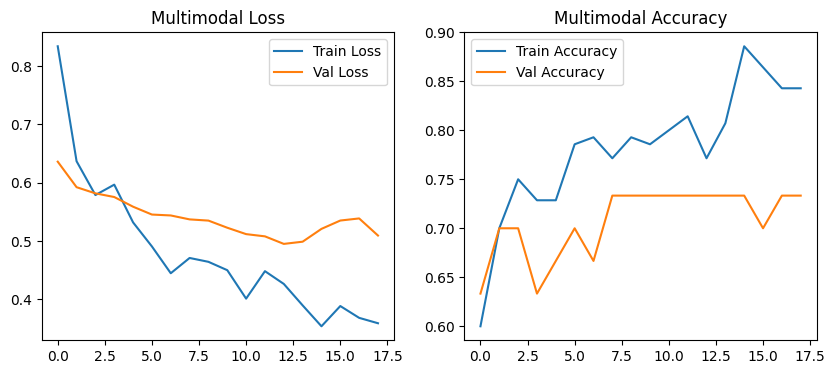

In [ ]:
plt.figure(figsize=(10,4))

plt.subplot(1,2,1)
plt.plot(history3.history["loss"], label="Train Loss")
plt.plot(history3.history["val_loss"], label="Val Loss")
plt.legend()
plt.title("Multimodal Loss")

plt.subplot(1,2,2)
plt.plot(history3.history["accuracy"], label="Train Accuracy")
plt.plot(history3.history["val_accuracy"], label="Val Accuracy")
plt.legend()
plt.title("Multimodal Accuracy")

plt.show()

In [ ]:
y_test_prob_multi = model3.predict(X_test_multi, verbose=0).ravel()
y_test_pred_multi = (y_test_prob_multi >= 0.35).astype(int)

print("Accuracy:", accuracy_score(y_test_multi, y_test_pred_multi))
print(classification_report(y_test_multi, y_test_pred_multi))
print("ROC AUC:", roc_auc_score(y_test_multi, y_test_prob_multi))

multimodal_metrics = get_metrics(y_test_multi, y_test_pred_multi, y_test_prob_multi)

Accuracy: 0.6
              precision    recall  f1-score   support

           0       0.75      0.50      0.60        18
           1       0.50      0.75      0.60        12

    accuracy                           0.60        30
   macro avg       0.62      0.62      0.60        30
weighted avg       0.65      0.60      0.60        30

ROC AUC: 0.736111111111111


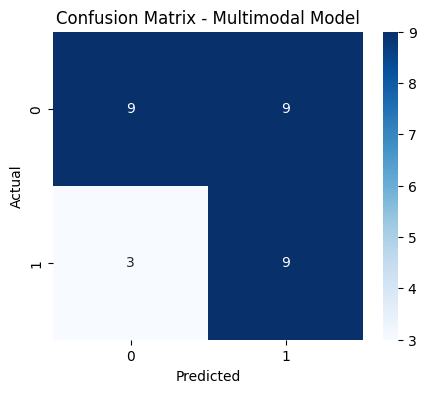

In [ ]:
cm = confusion_matrix(y_test_multi, y_test_pred_multi)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Multimodal Model")
plt.show()

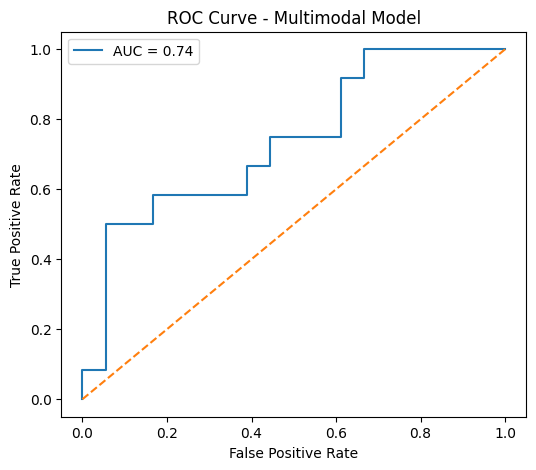

In [ ]:
fpr, tpr, _ = roc_curve(y_test_multi, y_test_prob_multi)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.2f}")
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Multimodal Model")
plt.legend()
plt.show()

### **Comparing all three models**

In [ ]:
results_df = pd.DataFrame([
    {"Model": "Clinical", **clinical_metrics},
    {"Model": "MRI", **mri_metrics},
    {"Model": "Multimodal", **multimodal_metrics}
])

display(results_df.round(2))

,Model,Accuracy,Recall (Class 1),F1 Score,ROC AUC
0,Clinical,0.75,0.50,0.62,0.79
1,MRI,0.40,1.00,0.57,0.44
2,Multimodal,0.60,0.75,0.60,0.74


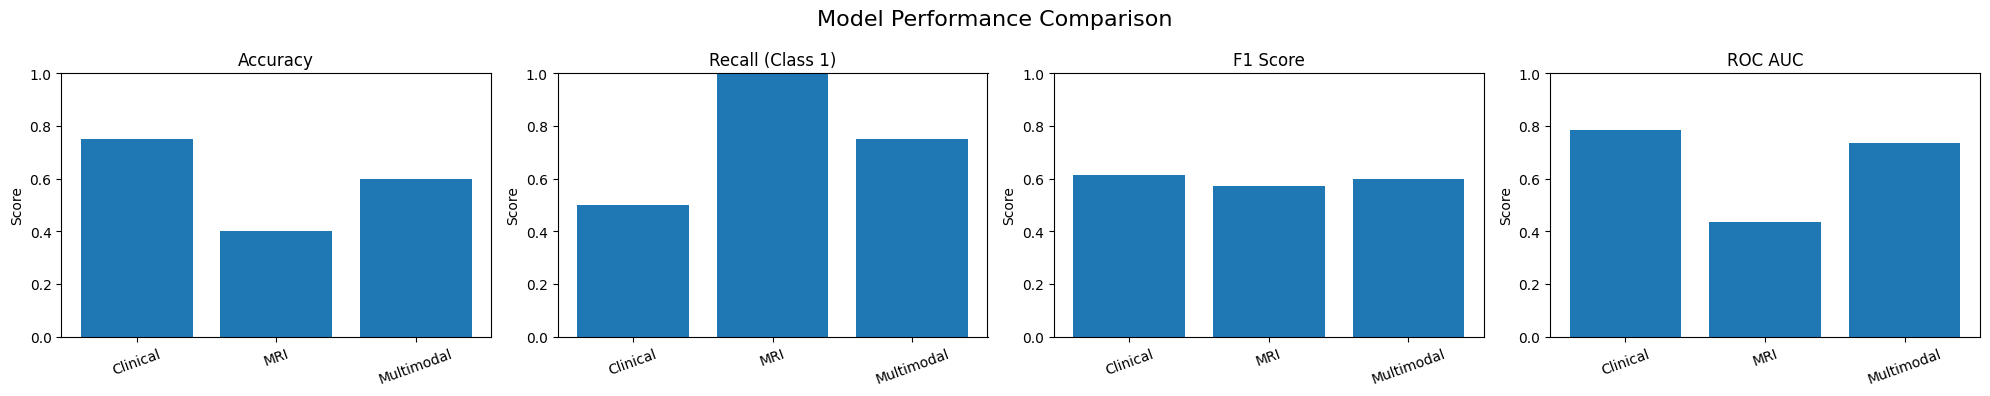

In [ ]:
metrics = ["Accuracy", "Recall (Class 1)", "F1 Score", "ROC AUC"]

# create one subplot per metric
fig, axes = plt.subplots(1, 4, figsize=(20, 4))

for i, metric in enumerate(metrics):
    axes[i].bar(results_df["Model"], results_df[metric])
    axes[i].set_title(metric)
    axes[i].set_ylim(0, 1)
    axes[i].set_ylabel("Score")
    axes[i].tick_params(axis='x', rotation=20)

plt.suptitle("Model Performance Comparison", fontsize=16)
plt.tight_layout()
plt.show()